/home/sasha/Documents/ucu-ai-hw-2/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


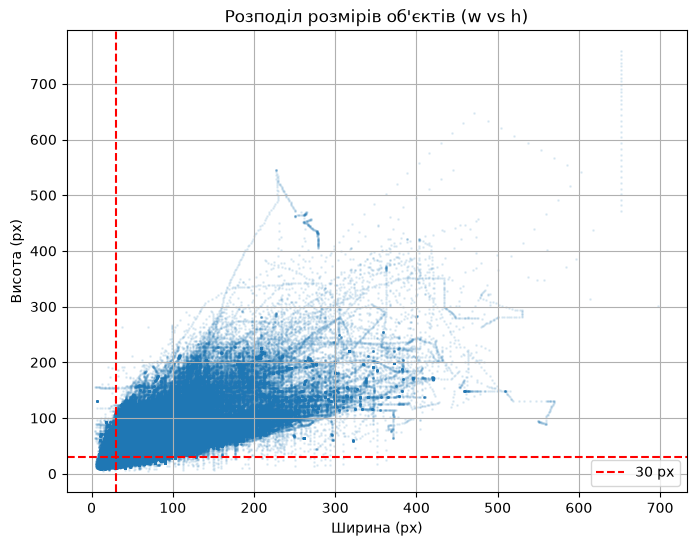

Кількість унікальних відео у кожному фолді:
fold
0    10
1    11
2    12
3    11
4    12
Name: clip, dtype: int64


In [4]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

# 1. Завантаження даних COCO (зміни шлях, якщо датасет лежить в іншому місці)
dataset_dir = '../train' 
with open(os.path.join(dataset_dir, 'annotations_coco.json'), 'r') as f:
    coco_data = json.load(f)

images_df = pd.DataFrame(coco_data['images'])
anns_df = pd.DataFrame(coco_data['annotations'])

# Відфільтруємо ігноровані зони (iscrowd = 1) для аналізу
valid_anns_df = anns_df[anns_df['iscrowd'] == 0].copy()

# 2. EDA: Розподіл розмірів BBox
# COCO bbox формат: [x, y, w, h]
valid_anns_df[['x', 'y', 'w', 'h']] = pd.DataFrame(valid_anns_df['bbox'].tolist(), index=valid_anns_df.index)

plt.figure(figsize=(8, 6))
plt.scatter(valid_anns_df['w'], valid_anns_df['h'], alpha=0.1, s=1)
plt.title("Розподіл розмірів об'єктів (w vs h)")
plt.xlabel("Ширина (px)")
plt.ylabel("Висота (px)")
plt.axvline(x=30, color='r', linestyle='--', label='30 px')
plt.axhline(y=30, color='r', linestyle='--')
plt.legend()
plt.grid(True)
plt.show()

# 3. Валідація: Sequence-level split (GroupKFold)
# Витягуємо назву кліпу зі шляху (наприклад, images/clip_01/001.jpg -> clip_01)
images_df['clip'] = images_df['file_name'].apply(lambda x: x.split('/')[1])

gkf = GroupKFold(n_splits=5)
images_df['fold'] = -1

# Розбиваємо так, щоб усі кадри одного кліпу потрапляли строго в один фолд
for fold, (train_idx, val_idx) in enumerate(gkf.split(X=images_df, groups=images_df['clip'])):
    images_df.loc[val_idx, 'fold'] = fold

# Перевірка: кількість унікальних кліпів у кожному фолді
print("Кількість унікальних відео у кожному фолді:")
print(images_df.groupby('fold')['clip'].nunique())

# Зберігаємо розбиття для подальшого використання
images_df.to_csv('cv_splits.csv', index=False)